In [60]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('marketing_campaign_data_messy.csv')

In [3]:
df.head()


,Campaign_ID,Campaign_Name,Start_Date,End_Date,Channel,Impressions,Clicks,Spend,Conversions,Active,Clicks,Campaign_Tag
0,CMP-00001,Q4_Summer_CMP-00001,2023-11-24 00:00:00,2023-12-13,TikTok,16795,197,$102.82,20.0,Y,NaN,TI
1,CMP-00002,Q1_Launch_CMP-00002,2023-05-06 00:00:00,2023-05-12,Facebook,1860,30,24.33,1.0,0,NaN,FA
2,CMP-00003,Q3_Winter_CMP-00003,2023-12-13 00:00:00,2023-12-20,Email,77820,843,1323.39,51.0,No,NaN,EM
3,CMP-00004,Q1_BlackFriday_CMP-00004,2023-10-30,2023-11-03,TikTok,55886,2019,2180.38,135.0,True,NaN,TI
4,CMP-00005,Q2_Winter_CMP-00005,2023-04-22 00:00:00,2023-04-23,Facebook,7265,169,252.44,30.0,Yes,NaN,FA


In [4]:
df.tail()

,Campaign_ID,Campaign_Name,Start_Date,End_Date,Channel,Impressions,Clicks,Spend,Conversions,Active,Clicks,Campaign_Tag
2015,CMP-00400,Q3_Summer_CMP-00400,2023-10-31 00:00:00,2023-11-13,TikTok,30592,586,$503.95,77.0,1,NaN,TI
2016,CMP-01255,Q4_Summer_CMP-01255,2023-09-01 00:00:00,2023-09-26,Google Ads,20097,897,1641.0,162.0,0,NaN,GO
2017,CMP-01050,Q2_Launch_CMP-01050,2023-02-09 00:00:00,2023-02-21,Instagram,33254,1117,883.82,214.0,0,NaN,IN
2018,CMP-01118,Q4_Winter_CMP-01118,2023-03-30 00:00:00,2023-04-27,Facebook,68728,2960,4198.5,591.0,Yes,NaN,FA
2019,CMP-01554,Q4_Launch_CMP-01554,2023-06-26 00:00:00,2023-07-09,Email,96402,1090,1315.59,66.0,Y,NaN,EM


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0    Campaign_ID   2020 non-null   str    
 1   Campaign_Name  2020 non-null   str    
 2   Start_Date     2020 non-null   str    
 3   End_Date       2020 non-null   str    
 4   Channel        1919 non-null   str    
 5   Impressions    2020 non-null   int64  
 6   Clicks         2020 non-null   int64  
 7   Spend          2020 non-null   str    
 8   Conversions    1820 non-null   float64
 9   Active         2020 non-null   str    
 10  Clicks         40 non-null     float64
 11  Campaign_Tag   2020 non-null   str    
dtypes: float64(2), int64(2), str(8)
memory usage: 338.2 KB


In [6]:
a=df.columns.tolist()
print(a)

[' Campaign_ID ', 'Campaign_Name', 'Start_Date', 'End_Date', 'Channel', 'Impressions', 'Clicks ', 'Spend', 'Conversions', 'Active', 'Clicks', 'Campaign_Tag']


In [10]:
#fix
df.columns=df.columns.str.strip().str.lower().str.replace(' ','_')
print(df.columns.tolist())


['campaign_id', 'campaign_name', 'start_date', 'end_date', 'channel', 'impressions', 'clicks', 'spend', 'conversions', 'active', 'clicks', 'campaign_tag']


In [15]:
dirty_spend_mask=df['spend'].astype(str).str.contains(r'\$')
print(df.loc[dirty_spend_mask,['campaign_name','campaign_id','spend']].head())


               campaign_name campaign_id     spend
0        Q4_Summer_CMP-00001   CMP-00001   $102.82
21  Q2_BlackFriday_CMP-00022   CMP-00022   $2428.4
22       Q4_Winter_CMP-00023   CMP-00023  $4726.22
31       Q2_Summer_CMP-00032   CMP-00032  $2759.35
32  Q2_BlackFriday_CMP-00033   CMP-00033  $2393.02
298


In [16]:
#how many $
print(dirty_spend_mask.sum())

298


In [21]:
dirty_spend_mask=df['spend'].astype(str).str.contains(r'\$')
print(df.loc[dirty_spend_mask,['campaign_name','campaign_id','spend']].head())
print("~~~~~~~~~~")
df['spend']=df['spend'].astype(str).str.replace(r'[^\d.-]','' ,regex=True )
df['spend']=pd.to_numeric(df['spend'])
print('Fix Applied')
print(dirty_spend_mask.sum())

Empty DataFrame
Columns: [campaign_name, campaign_id, spend]
Index: []
~~~~~~~~~~
Fix Applied
0


In [23]:
df.head()


,campaign_id,campaign_name,start_date,end_date,channel,impressions,clicks,spend,conversions,active,clicks,campaign_tag
0,CMP-00001,Q4_Summer_CMP-00001,2023-11-24 00:00:00,2023-12-13,TikTok,16795,197,102.82,20.0,Y,NaN,TI
1,CMP-00002,Q1_Launch_CMP-00002,2023-05-06 00:00:00,2023-05-12,Facebook,1860,30,24.33,1.0,0,NaN,FA
2,CMP-00003,Q3_Winter_CMP-00003,2023-12-13 00:00:00,2023-12-20,Email,77820,843,1323.39,51.0,No,NaN,EM
3,CMP-00004,Q1_BlackFriday_CMP-00004,2023-10-30,2023-11-03,TikTok,55886,2019,2180.38,135.0,True,NaN,TI
4,CMP-00005,Q2_Winter_CMP-00005,2023-04-22 00:00:00,2023-04-23,Facebook,7265,169,252.44,30.0,Yes,NaN,FA


In [24]:
c=df['channel'].unique()
print(c)

<ArrowStringArray>
[    'TikTok',   'Facebook',      'Email',  'Instagram', 'Google Ads',
     'E-mail',          nan,      'Gogle',    'Tik_Tok',    'Facebok',
 'Insta_gram']
Length: 11, dtype: str


In [26]:
cleanup={
    'Insta_gram':'Instagram',
    'Facebok': 'Facebook',
    'E-mail': 'Email',
    'Tik_Tok': 'TikTok',
    'Gogle' : 'Google Ads',
    'N/A': np.nan
}
df['channel']=df['channel'].replace(cleanup)
c=df['channel'].unique()
print('Fixed')
print(c)

Fixed
<ArrowStringArray>
['TikTok', 'Facebook', 'Email', 'Instagram', 'Google Ads', nan]
Length: 6, dtype: str


In [28]:
d=df['active'].unique()
print(d)

<ArrowStringArray>
['Y', '0', 'No', 'True', 'Yes', '1', 'False']
Length: 7, dtype: str


In [31]:
bol_fix={
    'Y' :  True,
    'Yes' : True,
    '1' : True,
    1: True,
    'No': False,
    '0':False,
    0: False
}
df['active']=df['active'].map(bol_fix).fillna(False).astype(bool)
print('Fixed')

Fixed


In [32]:
d=df['active'].unique()
print(d)

[ True False]


In [35]:
df['start_date'] = pd.to_datetime(
    df['start_date'], errors='coerce'
)

df['end_date'] = pd.to_datetime(
    df['end_date'], dayfirst=False, errors='coerce'
)

print('Fix Applied')
print(df['start_date'].dtype)

Fix Applied
datetime64[us]


In [42]:
df=df.loc[:, ~df.columns.duplicated()]

In [43]:
impossible_mask = df['clicks'] > df['impressions']

print(df.loc[impossible_mask, ['campaign_id', 'clicks', 'impressions']].head())

Empty DataFrame
Columns: [campaign_id, clicks, impressions]
Index: []


In [48]:
date_fix_mask=df['end_date']<df['start_date']
print(df.loc[date_fix_mask,['campaign_id','start_date','end_date']].head())
df.loc[date_fix_mask,'end_date']=df.loc[date_fix_mask,'start_date']+pd.Timedelta(days=30)
print('Fix Applied')

print(df.loc[date_fix_mask,['campaign_id','start_date','end_date']].head())

    campaign_id start_date   end_date
23    CMP-00024 2023-05-06 2023-05-01
54    CMP-00055 2023-09-01 2023-08-27
71    CMP-00072 2023-02-01 2023-01-27
156   CMP-00157 2023-12-06 2023-12-01
200   CMP-00201 2023-01-11 2023-01-06
Fix Applied
    campaign_id start_date   end_date
23    CMP-00024 2023-05-06 2023-06-05
54    CMP-00055 2023-09-01 2023-10-01
71    CMP-00072 2023-02-01 2023-03-03
156   CMP-00157 2023-12-06 2024-01-05
200   CMP-00201 2023-01-11 2023-02-10


In [54]:
#outliers handling
Q1=df['spend'].quantile(0.25)
Q3=df['spend'].quantile(0.25)
IQR=Q3-Q1
upper_limit=Q3+(3*IQR)
outlier_mask=df['spend']>upper_limit
print(df.loc[outlier_mask,['campaign_id','campaign_name']].head())
print('Fix applied')
df.loc[outlier_mask,'spend']=upper_limit
print(df.loc[outlier_mask,['campaign_id','campaign_name']].head())

  campaign_id             campaign_name
2   CMP-00003       Q3_Winter_CMP-00003
3   CMP-00004  Q1_BlackFriday_CMP-00004
5   CMP-00006  Q4_BlackFriday_CMP-00006
6   CMP-00007       Q3_Launch_CMP-00007
7   CMP-00008       Q4_Launch_CMP-00008
Fix applied
  campaign_id             campaign_name
2   CMP-00003       Q3_Winter_CMP-00003
3   CMP-00004  Q1_BlackFriday_CMP-00004
5   CMP-00006  Q4_BlackFriday_CMP-00006
6   CMP-00007       Q3_Launch_CMP-00007
7   CMP-00008       Q4_Launch_CMP-00008


In [57]:
#feature extraction
df['season']= df['campaign_name'].str.extract(r'Q\d_([^_]+)_')
print("Fix Applied")
print(df[['campaign_name','season']].head())

Fix Applied
              campaign_name       season
0       Q4_Summer_CMP-00001       Summer
1       Q1_Launch_CMP-00002       Launch
2       Q3_Winter_CMP-00003       Winter
3  Q1_BlackFriday_CMP-00004  BlackFriday
4       Q2_Winter_CMP-00005       Winter


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   campaign_id    2020 non-null   str           
 1   campaign_name  2020 non-null   str           
 2   start_date     1687 non-null   datetime64[us]
 3   end_date       2020 non-null   datetime64[us]
 4   channel        1919 non-null   str           
 5   impressions    2020 non-null   int64         
 6   clicks         2020 non-null   int64         
 7   spend          2020 non-null   float64       
 8   conversions    1820 non-null   float64       
 9   active         2020 non-null   bool          
 10  campaign_tag   2020 non-null   str           
 11  season         2020 non-null   str           
dtypes: bool(1), datetime64[us](2), float64(2), int64(2), str(5)
memory usage: 266.5 KB


In [61]:
print("Missing values check:")
print(df[['spend', 'conversions', 'season', 'channel']].isnull().sum())

# Drop rows where channel is missing since we can't optimize an unknown channel
df = df.dropna(subset=['channel']).copy()

Missing values check:
spend            0
conversions    200
season           0
channel        101
dtype: int64


In [62]:
# Use np.where to prevent "Division by Zero" errors if a campaign had 0 conversions
df['CPA'] = np.where(df['conversions'] > 0, df['spend'] / df['conversions'], np.nan)
df['conversion_rate'] = np.where(df['clicks'] > 0, (df['conversions'] / df['clicks']) * 100, 0)

print("Sample of campaign-level CPA:")
display(df[['campaign_id', 'channel', 'spend', 'conversions', 'CPA']].head())

Sample of campaign-level CPA:


,campaign_id,channel,spend,conversions,CPA
0,CMP-00001,TikTok,102.8200,20.0,5.141000
1,CMP-00002,Facebook,24.3300,1.0,24.330000
2,CMP-00003,Email,649.9975,51.0,12.745049
3,CMP-00004,TikTok,649.9975,135.0,4.814796
4,CMP-00005,Facebook,252.4400,30.0,8.414667


In [63]:
# Calculate blended metrics (total spend / total conversions for the group)
# Never average the CPA column directly—it skews the results
seasonal_strategy = df.groupby(['season', 'channel']).agg({
    'spend': 'sum',
    'conversions': 'sum',
    'campaign_id': 'count'
}).reset_index()

seasonal_strategy.rename(columns={'campaign_id': 'campaign_count'}, inplace=True)
seasonal_strategy['blended_CPA'] = seasonal_strategy['spend'] / seasonal_strategy['conversions']

display(seasonal_strategy.head())

,season,channel,spend,conversions,campaign_count,blended_CPA
0,BlackFriday,Email,50180.9350,13919.0,90,3.605211
1,BlackFriday,Facebook,59325.7725,17979.0,106,3.299726
2,BlackFriday,Google Ads,44851.8975,10774.0,80,4.162975
3,BlackFriday,Instagram,53379.1550,17429.0,95,3.062663
4,BlackFriday,TikTok,60890.9325,18834.0,111,3.233032


In [64]:
# Sort from cheapest to most expensive CPA within each season
seasonal_strategy = seasonal_strategy.sort_values(by=['season', 'blended_CPA'], ascending=[True, True])

# Extract the #1 best performing channel for every season
top_channels_per_season = seasonal_strategy.groupby('season').first().reset_index()

print("Top Performing Channels by Season (Lowest CPA):")
display(top_channels_per_season[['season', 'channel', 'blended_CPA', 'spend']])

Top Performing Channels by Season (Lowest CPA):


,season,channel,blended_CPA,spend
0,BlackFriday,Instagram,3.062663,53379.1550
1,Launch,Facebook,2.832099,48377.9075
2,Summer,Google Ads,2.891219,44926.6525
3,Winter,Facebook,3.185654,61951.4150


In [68]:
# Find which content/messaging works best in each season
tag_performance = df.groupby(['season', 'campaign_tag']).agg({
    'spend': 'sum',
    'conversions': 'sum'
}).reset_index()

tag_performance['tag_CPA'] = tag_performance['spend'] / tag_performance['conversions']

# Sort to see the best tags at the top
tag_performance = tag_performance.sort_values(by=['season', 'tag_CPA'])

print("Top 5 Most Efficient Campaign Tags:")
display(tag_performance.head())

Top 5 Most Efficient Campaign Tags:


,season,campaign_tag,spend,conversions,tag_CPA
5,BlackFriday,INVALID,8005.9950,3006.0,2.663338
4,BlackFriday,IN,51429.1625,16872.0,3.048196
6,BlackFriday,TI,58290.9425,17769.0,3.280485
2,BlackFriday,FA,58025.7775,17511.0,3.313676
1,BlackFriday,EM,44437.8625,12198.0,3.643045


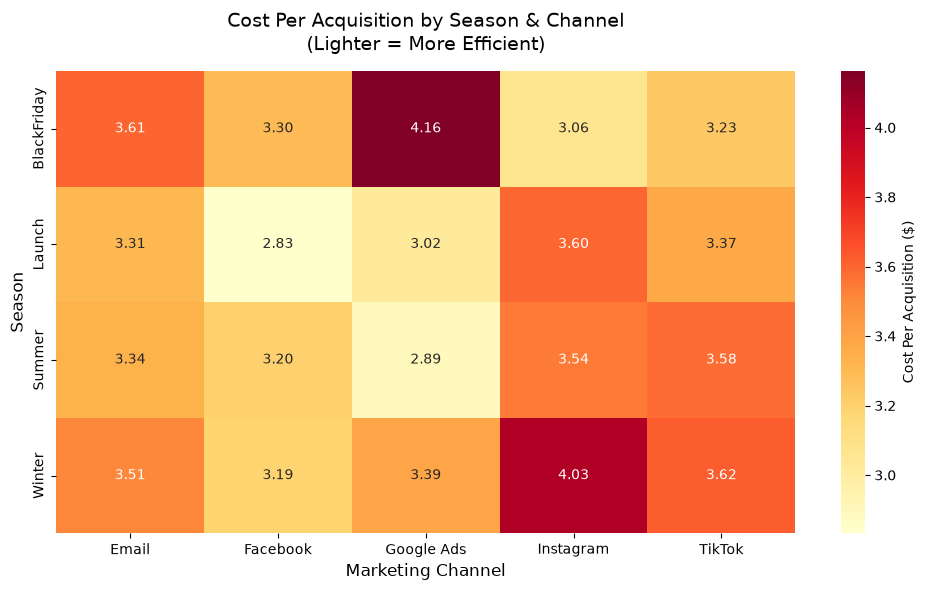

In [69]:
plt.figure(figsize=(10, 6))

# Pivot the data so Seasons are rows and Channels are columns
heatmap_data = seasonal_strategy.pivot(index='season', columns='channel', values='blended_CPA')

# Draw the heatmap (Darker colors = higher cost/bad, Lighter = cheaper/good)
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={'label': 'Cost Per Acquisition ($)'})

plt.title('Cost Per Acquisition by Season & Channel\n(Lighter = More Efficient)', fontsize=14, pad=15)
plt.xlabel('Marketing Channel', fontsize=12)
plt.ylabel('Season', fontsize=12)
plt.tight_layout()
plt.show()

In [67]:
# Sort from cheapest to most expensive CPA within each season
seasonal_strategy = seasonal_strategy.sort_values(by=['season', 'blended_CPA'], ascending=[True, True])

# Extract the #1 best performing channel for every season
top_channels_per_season = seasonal_strategy.groupby('season').first().reset_index()

print("Top Performing Channels by Season (Lowest CPA):")
display(top_channels_per_season[['season', 'channel', 'blended_CPA', 'spend']])

Top Performing Channels by Season (Lowest CPA):


,season,channel,blended_CPA,spend
0,BlackFriday,Instagram,3.062663,53379.1550
1,Launch,Facebook,2.832099,48377.9075
2,Summer,Google Ads,2.891219,44926.6525
3,Winter,Facebook,3.185654,61951.4150


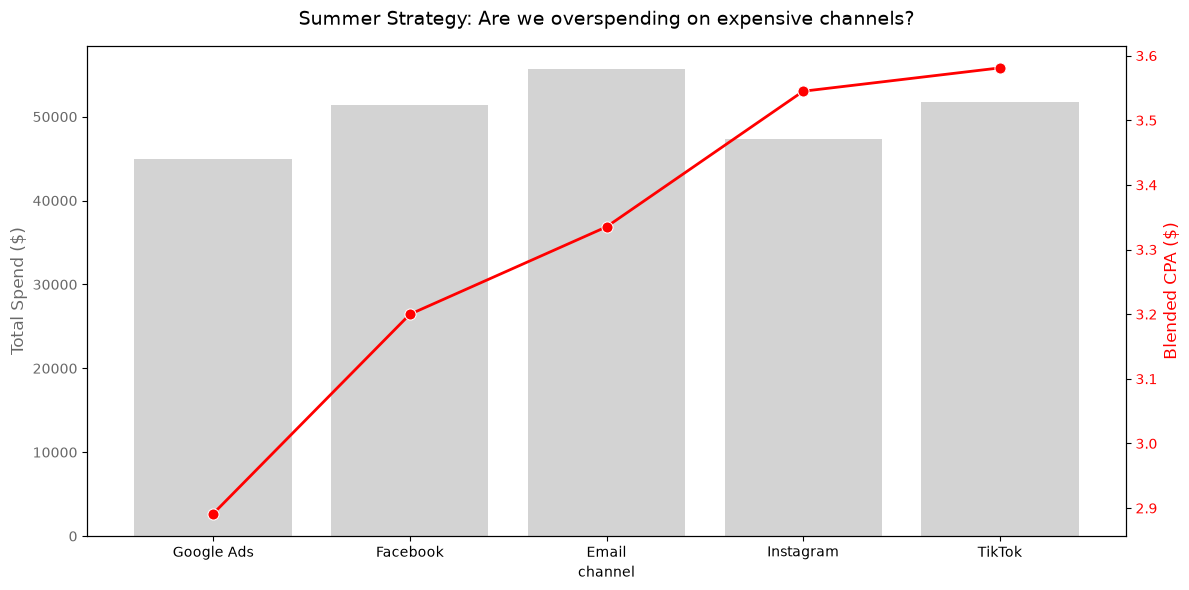

In [70]:
# Change this variable to analyze a specific season (e.g., 'Summer', 'Winter')
target_season = 'Summer' 
season_data = seasonal_strategy[seasonal_strategy['season'] == target_season].copy()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Left Y-Axis: Total Spend (Bar Chart)
sns.barplot(data=season_data, x='channel', y='spend', color='lightgray', ax=ax1)
ax1.set_ylabel('Total Spend ($)', color='dimgray', fontsize=12)
ax1.tick_params(axis='y', labelcolor='dimgray')

# Right Y-Axis: Blended CPA (Line Chart)
ax2 = ax1.twinx()
sns.lineplot(data=season_data, x='channel', y='blended_CPA', color='red', 
             marker='o', linewidth=2, markersize=8, ax=ax2)
ax2.set_ylabel('Blended CPA ($)', color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

plt.title(f'{target_season} Strategy: Are we overspending on expensive channels?', fontsize=14, pad=15)
ax1.grid(False)
ax2.grid(False)
plt.tight_layout()
plt.show()